# Graph EDA và feature cấu trúc (P1)

P1 so sánh giao dịch licit và illicit trong Bitcoin Elliptic rồi tạo feature đồ thị cho P2. Mỗi node là một giao dịch. Cạnh `A → B` nghĩa là B sử dụng đầu ra của A.

Chọn kernel `pytorch` và bấm **Run All**. Notebook đọc file `data/processed/processed_data.npz` của P0, gồm mã giao dịch, timestep, cạnh và nhãn.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import mannwhitneyu

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "processed_data.npz"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy {data_path}. Mở repo trong VS Code và đặt file của P0 "
        "vào data/processed/processed_data.npz."
    )

with np.load(data_path, allow_pickle=False) as data:
    node_timesteps = data["timestep"]
    tx_ids = data["tx_ids"]
    edge_index = data["edge_index"]
    labels = data["y"]

print(f"Đã nạp {len(tx_ids):,} giao dịch từ {data_path}")

Đã nạp 203,769 giao dịch từ d:\BTL_AIT3003_ULB-Credit-Card-Fraud\data\processed\processed_data.npz


## 1. Dựng snapshot và thống kê theo timestep

Dựng đồ thị có hướng cho từng timestep. Giữ node `unknown` để tính đúng cấu trúc. **Liên thông yếu** nghĩa là các node nối được khi bỏ qua hướng cạnh.

In [2]:
def build_snapshot(
    node_timesteps: np.ndarray, edge_index: np.ndarray, timestep: int
) -> nx.DiGraph:
    """Use P0's row indices as node IDs and preserve source-to-target direction."""
    if edge_index.ndim != 2 or edge_index.shape[0] != 2:
        raise ValueError("edge_index must have shape (2, number of edges).")
    if np.any(edge_index < 0) or np.any(edge_index >= len(node_timesteps)):
        raise ValueError("edge_index contains an out-of-range node index.")

    snapshot_mask = node_timesteps == timestep
    node_indices = np.flatnonzero(snapshot_mask).tolist()
    if not node_indices:
        raise ValueError(f"No transactions found for timestep {timestep}.")

    sources, targets = edge_index
    source_mask = snapshot_mask[sources]
    target_mask = snapshot_mask[targets]
    if np.any(source_mask != target_mask):
        raise ValueError(f"A directed edge crosses the boundary of timestep {timestep}.")

    graph = nx.DiGraph()
    graph.add_nodes_from(node_indices)
    graph.add_edges_from(edge_index[:, source_mask].T.tolist())
    if graph.number_of_edges() != np.count_nonzero(source_mask):
        raise ValueError(f"Duplicate directed edges found in timestep {timestep}.")

    return graph


timesteps = np.unique(node_timesteps)
assert np.array_equal(timesteps, np.arange(1, 50)), "Expected timesteps 1 through 49."
assert np.isin(labels, [-1, 0, 1]).all(), "Unexpected class label."

in_degree = np.zeros(len(tx_ids), dtype=np.int64)
out_degree = np.zeros(len(tx_ids), dtype=np.int64)
pagerank = np.empty(len(tx_ids), dtype=np.float64)
clustering = np.empty(len(tx_ids), dtype=np.float64)
core_number = np.empty(len(tx_ids), dtype=np.int64)
snapshot_rows = []

for timestep in timesteps:
    graph = build_snapshot(node_timesteps, edge_index, int(timestep))
    node_indices = list(graph)
    snapshot_labels = labels[node_indices]
    in_degree[node_indices] = [graph.in_degree(node) for node in node_indices]
    out_degree[node_indices] = [graph.out_degree(node) for node in node_indices]

    snapshot_pagerank = nx.pagerank(graph, alpha=0.85, max_iter=200, tol=1e-12)
    undirected_graph = graph.to_undirected()
    snapshot_clustering = nx.clustering(undirected_graph)
    snapshot_core = nx.core_number(undirected_graph)
    pagerank[node_indices] = [snapshot_pagerank[node] for node in node_indices]
    clustering[node_indices] = [snapshot_clustering[node] for node in node_indices]
    core_number[node_indices] = [snapshot_core[node] for node in node_indices]

    snapshot_rows.append(
        {
            "timestep": timestep,
            "node_count": graph.number_of_nodes(),
            "edge_count": graph.number_of_edges(),
            "weak_component_count": nx.number_weakly_connected_components(graph),
            "licit_count": np.count_nonzero(snapshot_labels == 0),
            "illicit_count": np.count_nonzero(snapshot_labels == 1),
            "unknown_count": np.count_nonzero(snapshot_labels == -1),
        }
    )

snapshot_summary = pd.DataFrame(snapshot_rows)
labeled_count = snapshot_summary["licit_count"] + snapshot_summary["illicit_count"]
snapshot_summary["illicit_rate_labeled"] = snapshot_summary["illicit_count"].div(
    labeled_count.replace(0, np.nan)
)
snapshot_summary["unknown_rate"] = snapshot_summary["unknown_count"].div(
    snapshot_summary["node_count"]
)

display(snapshot_summary.head())

,timestep,node_count,edge_count,weak_component_count,licit_count,illicit_count,unknown_count,illicit_rate_labeled,unknown_rate
0,1,7880,9164,1,2130,17,5733,0.007918,0.727538
1,2,4544,5241,1,1099,18,3427,0.016115,0.754181
2,3,6621,8316,1,1268,11,5342,0.008600,0.806827
3,4,5693,8180,1,1410,30,4253,0.020833,0.747058
4,5,6803,8623,1,1874,8,4921,0.004251,0.723357


### Kiểm tra và xuất bảng

Kiểm tra tổng node, cạnh và số giao dịch theo nhãn. Tổng bậc vào và tổng bậc ra đều phải bằng số cạnh. Bảng degree theo đúng thứ tự node của P0.

In [3]:
degree_features = pd.DataFrame(
    {
        "node_idx": np.arange(len(tx_ids)),
        "tx_id": tx_ids,
        "in_degree": in_degree,
        "out_degree": out_degree,
    }
)

assert snapshot_summary["node_count"].sum() == len(degree_features) == 203_769
assert snapshot_summary["edge_count"].sum() == edge_index.shape[1] == 234_355
assert np.array_equal(degree_features["tx_id"].to_numpy(), tx_ids)
assert (degree_features[["in_degree", "out_degree"]].sum() == edge_index.shape[1]).all()
assert (
    snapshot_summary[["licit_count", "illicit_count", "unknown_count"]].sum(axis=1)
    == snapshot_summary["node_count"]
).all()

tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
snapshot_summary.to_csv(tables_dir / "graph_snapshot_summary.csv", index=False)
degree_features.to_csv(tables_dir / "graph_degree_all_timesteps.csv", index=False)

print(f"Đã xuất {len(snapshot_summary):,} snapshot và {len(degree_features):,} dòng degree.")
display(degree_features.head())

Đã xuất 49 snapshot và 203,769 dòng degree.


,node_idx,tx_id,in_degree,out_degree
0,0,230425980,1,1
1,1,5530458,1,1
2,2,232022460,1,2
3,3,232438397,160,1
4,4,230460314,2,8


### Tỷ lệ nhãn theo timestep

Tỷ lệ illicit tính trên **giao dịch đã có nhãn**. Tỷ lệ unknown tính trên **toàn bộ giao dịch** trong snapshot.

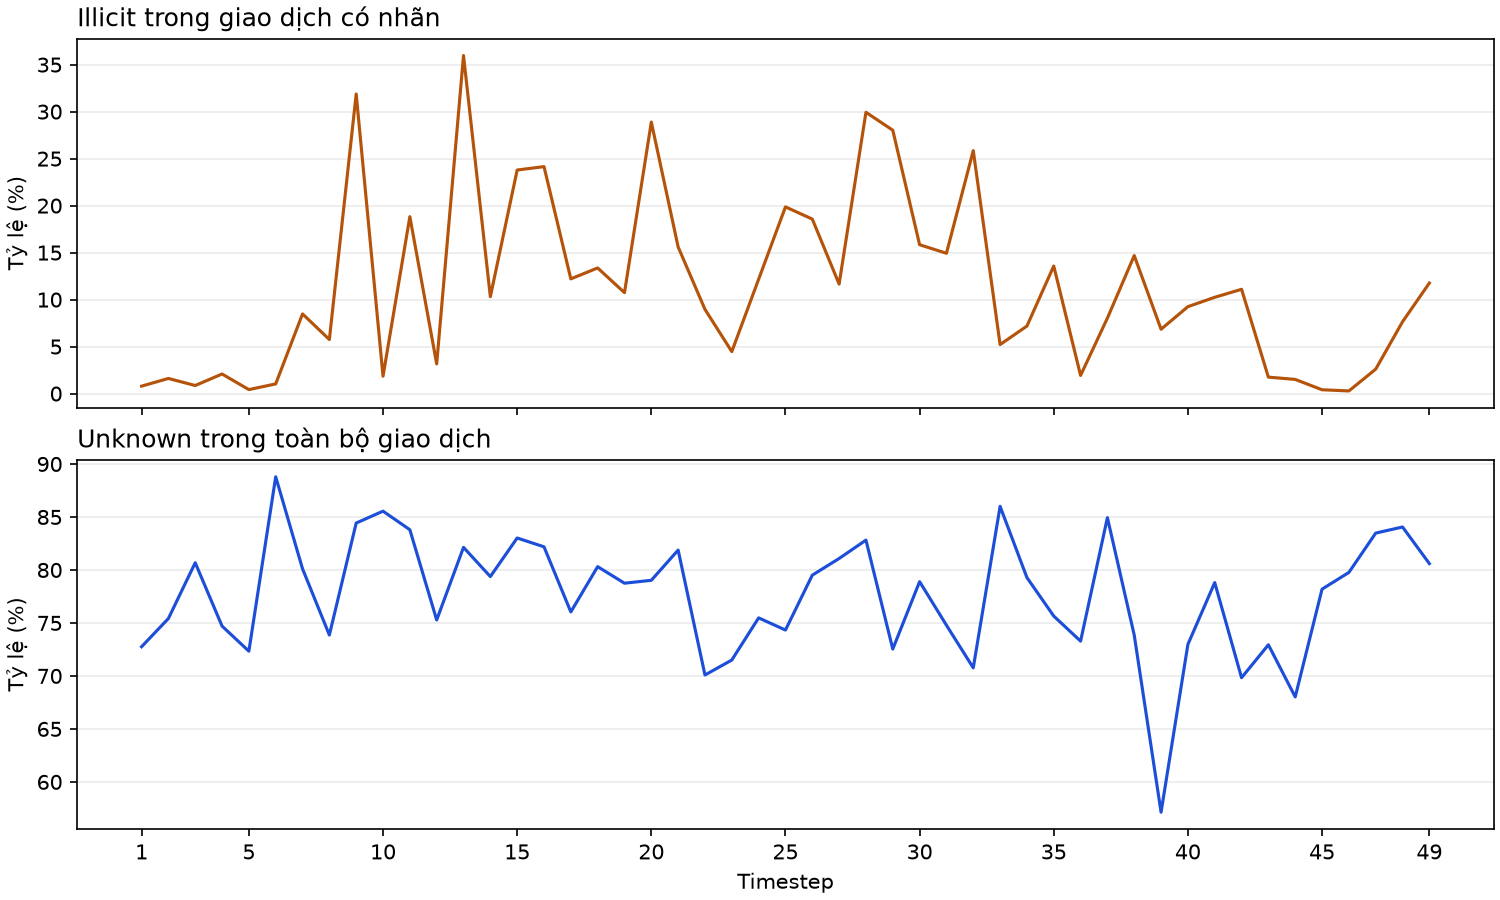

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
for axis, column, title, color in (
    (axes[0], "illicit_rate_labeled", "Illicit trong giao dịch có nhãn", "#b45309"),
    (axes[1], "unknown_rate", "Unknown trong toàn bộ giao dịch", "#1d4ed8"),
):
    axis.plot(
        snapshot_summary["timestep"], snapshot_summary[column] * 100, color=color
    )
    axis.set_title(title, loc="left")
    axis.set_ylabel("Tỷ lệ (%)")
    axis.grid(axis="y", alpha=0.25)

axes[-1].set_xlabel("Timestep")
axes[-1].set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 49])

figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
figure_path = figures_dir / "graph_label_rates_by_timestep.png"
fig.savefig(figure_path, dpi=150)
plt.close(fig)
display(Image(filename=str(figure_path)))

### Phân phối bậc vào và bậc ra theo snapshot

Mỗi cột là một timestep. Mỗi hàng là một khoảng bậc. Màu biểu thị tỷ lệ giao dịch trên thang log, ô xám là 0%.

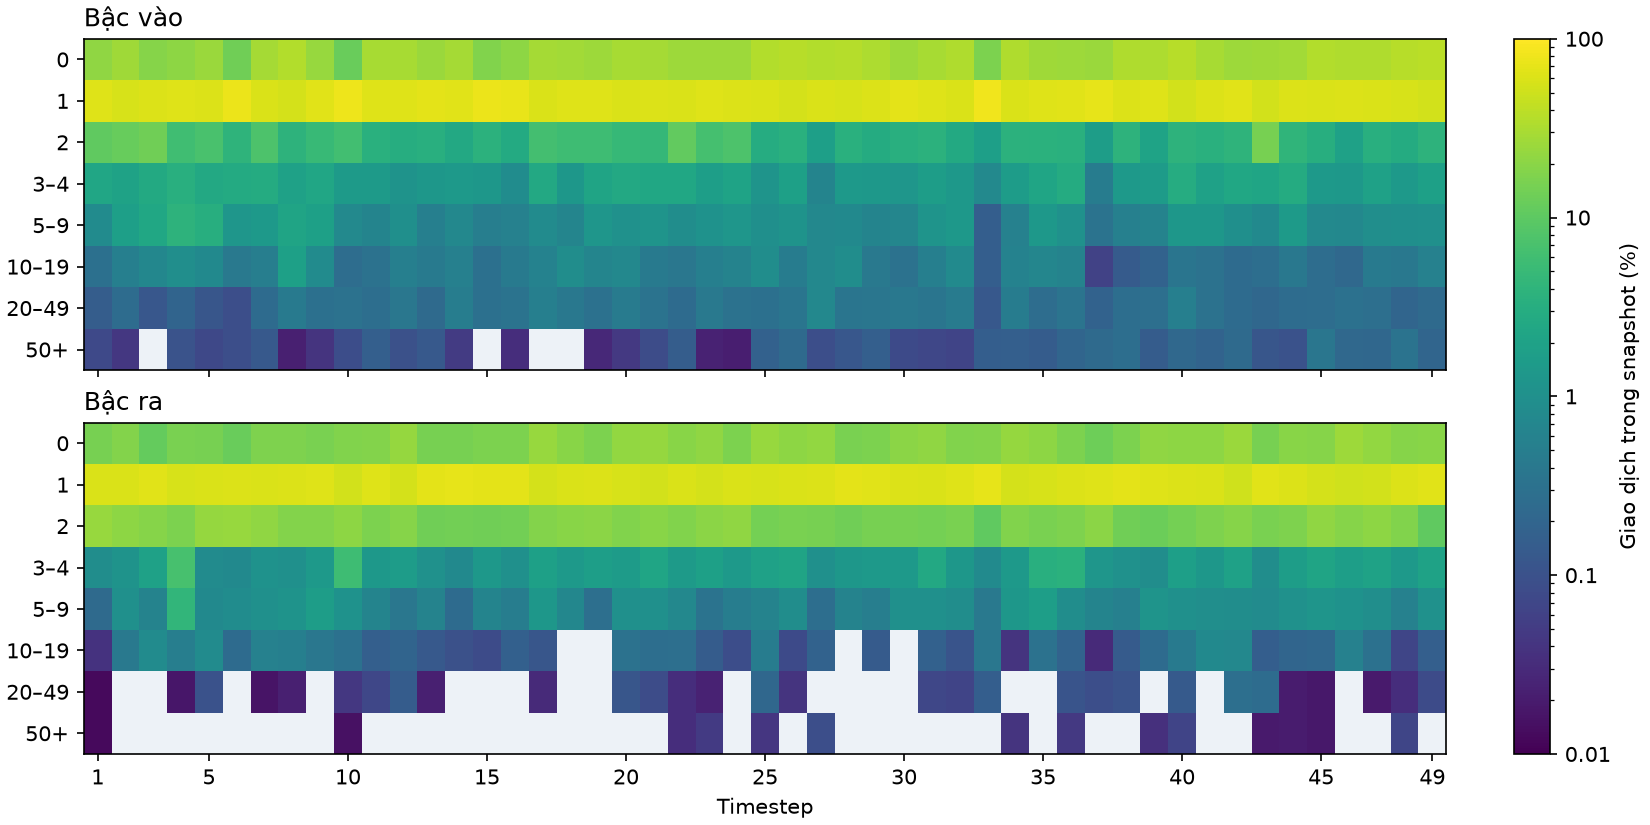

In [5]:
from matplotlib.colors import LogNorm

degree_distribution = (
    degree_features.assign(timestep=node_timesteps)
    .melt(id_vars="timestep", value_vars=["in_degree", "out_degree"],
          var_name="degree_type", value_name="degree")
    .groupby(["timestep", "degree_type", "degree"])
    .size()
    .rename("node_count")
    .reset_index()
)
nodes_per_group = degree_distribution.groupby(["timestep", "degree_type"])["node_count"]
degree_distribution["node_fraction"] = degree_distribution["node_count"] / nodes_per_group.transform("sum")
np.testing.assert_allclose(
    degree_distribution.groupby(["timestep", "degree_type"])["node_fraction"].sum(), 1
)
degree_distribution.to_csv(tables_dir / "graph_degree_distribution_by_timestep.csv", index=False)

degree_bins = ["0", "1", "2", "3–4", "5–9", "10–19", "20–49", "50+"]
binned_degrees = degree_distribution.assign(
    degree_bin=pd.cut(
        degree_distribution["degree"], [-1, 0, 1, 2, 4, 9, 19, 49, np.inf], labels=degree_bins
    )
)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, layout="constrained")
for axis, column, title in zip(axes, ["in_degree", "out_degree"], ["Bậc vào", "Bậc ra"]):
    heatmap = (
        binned_degrees.loc[binned_degrees["degree_type"] == column]
        .pivot_table(index="degree_bin", columns="timestep", values="node_fraction",
                     aggfunc="sum", observed=False, fill_value=0)
        .reindex(index=degree_bins, columns=timesteps, fill_value=0)
        * 100
    )
    values = np.ma.masked_equal(heatmap.to_numpy(), 0)
    image = axis.imshow(values, aspect="auto", cmap="viridis", norm=LogNorm(vmin=0.01, vmax=100))
    axis.set_facecolor("#edf2f7")
    axis.set_yticks(range(len(degree_bins)), labels=degree_bins)
    axis.set_title(title, loc="left")

axes[-1].set_xticks([0, 4, 9, 14, 19, 24, 29, 34, 39, 44, 48],
                    labels=[1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 49])
axes[-1].set_xlabel("Timestep")
fig.colorbar(image, ax=axes, label="Giao dịch trong snapshot (%)",
             ticks=[0.01, 0.1, 1, 10, 100], format="%g")
degree_distribution_path = figures_dir / "graph_degree_distribution_by_timestep.png"
fig.savefig(degree_distribution_path, dpi=150)
plt.close(fig)
display(Image(filename=str(degree_distribution_path)))

## 2. So sánh feature giữa licit và illicit

Mann–Whitney U so sánh thứ hạng của hai nhóm có nhãn. Rank-biserial dương nghĩa là illicit thường cao hơn, âm nghĩa là thường thấp hơn. Trên biểu đồ tích lũy, tại `x = 1` ta đọc được tỷ lệ giao dịch có bậc tối đa 1.

In [6]:
def compare_by_label(licit_features: pd.DataFrame, illicit_features: pd.DataFrame) -> pd.DataFrame:
    comparison_rows = []
    for metric in licit_features.columns:
        licit = licit_features[metric]
        illicit = illicit_features[metric]
        test = mannwhitneyu(illicit, licit, alternative="two-sided", method="asymptotic")
        comparison_rows.append(
            {
                "metric": metric,
                "licit_count": len(licit),
                "illicit_count": len(illicit),
                "licit_median": licit.median(),
                "illicit_median": illicit.median(),
                "licit_p95": licit.quantile(0.95),
                "illicit_p95": illicit.quantile(0.95),
                "mann_whitney_u_illicit": test.statistic,
                "p_value": test.pvalue,
                "rank_biserial": 2 * test.statistic / (len(illicit) * len(licit)) - 1,
            }
        )
    return pd.DataFrame(comparison_rows)


degree_metrics = {"in_degree": "Bậc vào", "out_degree": "Bậc ra"}
licit_degrees = degree_features.loc[labels == 0, list(degree_metrics)]
illicit_degrees = degree_features.loc[labels == 1, list(degree_metrics)]

degree_comparison = compare_by_label(licit_degrees, illicit_degrees)
degree_comparison.to_csv(tables_dir / "graph_degree_class_comparison.csv", index=False)
display(degree_comparison)

,metric,licit_count,illicit_count,licit_median,illicit_median,licit_p95,illicit_p95,mann_whitney_u_illicit,p_value,rank_biserial
0,in_degree,42019,4545,1.0,1.0,6.0,1.0,90293567.5,5.552428e-11,-0.054401
1,out_degree,42019,4545,1.0,1.0,2.0,2.0,77335837.5,1.441678e-118,-0.190100


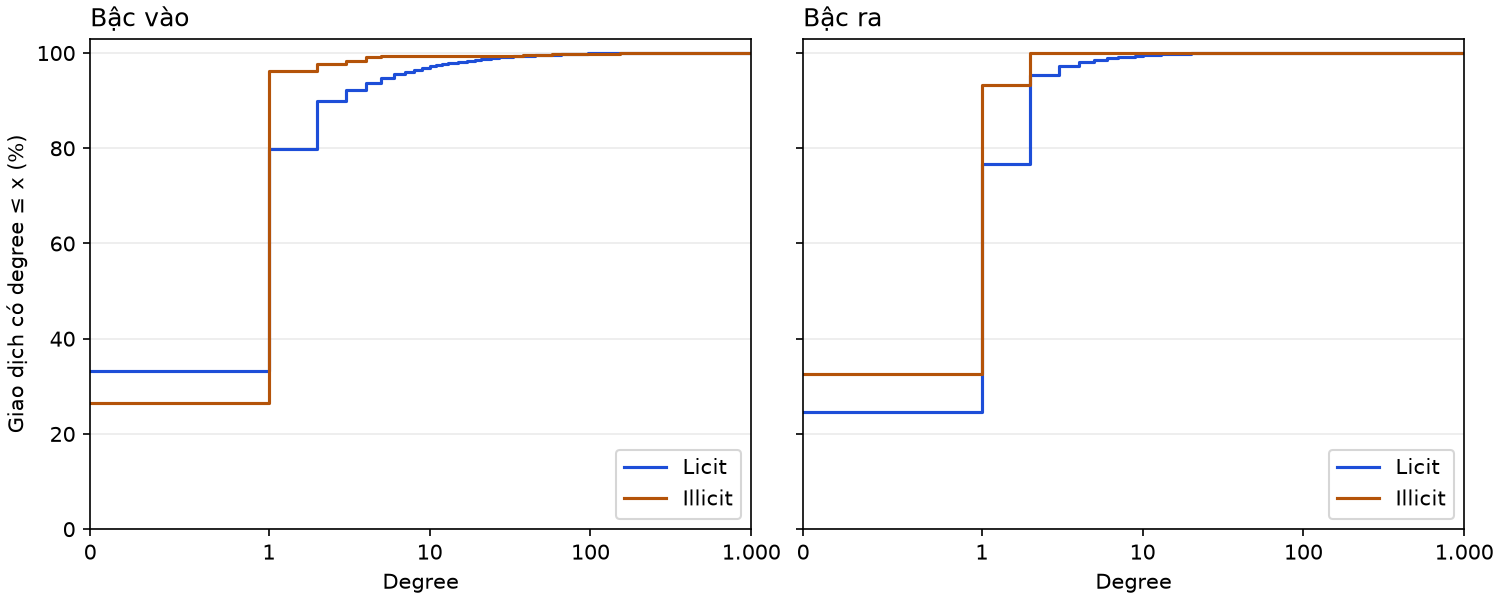

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
right_limit = max(1_000, int(licit_degrees.max().max()), int(illicit_degrees.max().max()))
for axis, (metric, title) in zip(axes, degree_metrics.items()):
    for label, group, color in (
        ("Licit", licit_degrees, "#1d4ed8"),
        ("Illicit", illicit_degrees, "#b45309"),
    ):
        values, counts = np.unique(group[metric], return_counts=True)
        cumulative_percent = counts.cumsum() / counts.sum() * 100
        axis.step(
            np.append(values, right_limit), np.append(cumulative_percent, 100),
            where="post", label=label, color=color,
        )

    axis.set_title(title, loc="left")
    axis.set_xlabel("Degree")
    axis.set_xscale("symlog", linthresh=1)
    axis.set_xlim(0, right_limit)
    axis.set_ylim(0, 103)
    axis.set_xticks([0, 1, 10, 100, 1_000], labels=["0", "1", "10", "100", "1.000"])
    axis.grid(axis="y", alpha=0.25)
    axis.legend(loc="lower right")

axes[0].set_ylabel("Giao dịch có degree ≤ x (%)")
degree_figure_path = figures_dir / "graph_degree_class_comparison.png"
fig.savefig(degree_figure_path, dpi=150)
plt.close(fig)
display(Image(filename=str(degree_figure_path)))

### PageRank, clustering và core number

- **PageRank** đo mức độ nổi bật dựa trên các cạnh có hướng đi vào. Tổng điểm mỗi snapshot bằng 1.
- **Clustering** đo tỷ lệ cặp láng giềng có cạnh nối.
- **Core number** là k lớn nhất để node thuộc một nhóm mà mỗi node còn ít nhất k láng giềng nội bộ.

Clustering và core number tính trên đồ thị bỏ hướng.

In [8]:
structural_features = degree_features.assign(
    pagerank=pagerank,
    clustering=clustering,
    core_number=core_number,
)

pagerank_by_timestep = np.bincount(node_timesteps, weights=pagerank)[1:]
np.testing.assert_allclose(pagerank_by_timestep, 1, rtol=0, atol=1e-10)
assert np.isfinite(pagerank).all() and (pagerank > 0).all()
assert ((clustering >= 0) & (clustering <= 1)).all()
assert (core_number >= 0).all()

structural_features.to_csv(tables_dir / "graph_structural_features.csv", index=False)

structural_metrics = {
    "pagerank": ("PageRank", "log"),
    "clustering": ("Clustering coefficient", "linear"),
    "core_number": ("Core number", "linear"),
}
licit_structure = structural_features.loc[labels == 0, list(structural_metrics)]
illicit_structure = structural_features.loc[labels == 1, list(structural_metrics)]
structural_comparison = compare_by_label(licit_structure, illicit_structure)
structural_comparison.to_csv(tables_dir / "graph_structural_class_comparison.csv", index=False)
display(structural_comparison)

,metric,licit_count,illicit_count,licit_median,illicit_median,licit_p95,illicit_p95,mann_whitney_u_illicit,p_value,rank_biserial
0,pagerank,42019,4545,0.000118,0.000134,0.000744,0.000473,106451767.5,3.734902e-37,0.114816
1,clustering,42019,4545,0.000000,0.000000,0.000000,0.000000,92208402.0,1.103216e-31,-0.034347
2,core_number,42019,4545,1.000000,1.000000,2.000000,2.000000,78992918.5,1.335711e-119,-0.172747


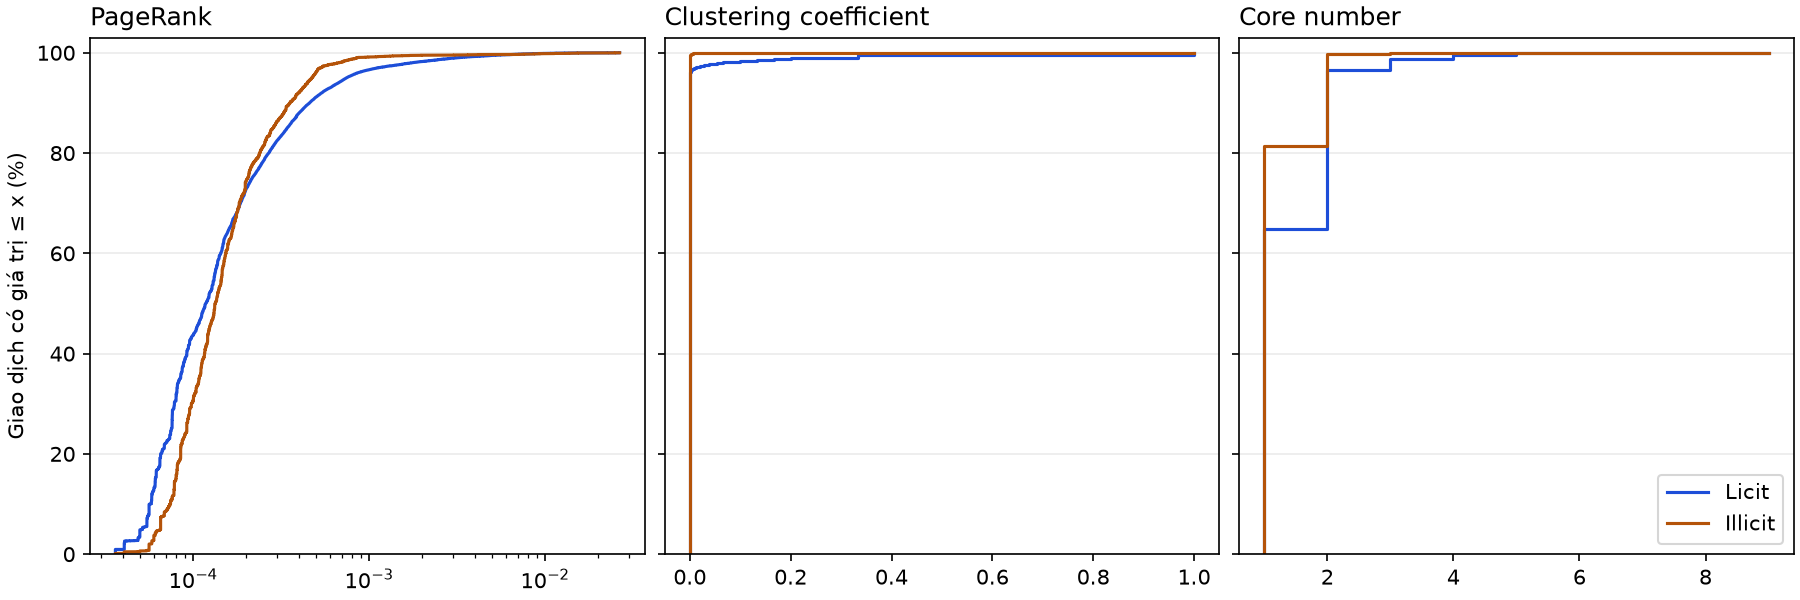

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")
for axis, (metric, (title, scale)) in zip(axes, structural_metrics.items()):
    lower = min(licit_structure[metric].min(), illicit_structure[metric].min())
    upper = max(licit_structure[metric].max(), illicit_structure[metric].max())
    for label, group, color in (
        ("Licit", licit_structure, "#1d4ed8"),
        ("Illicit", illicit_structure, "#b45309"),
    ):
        values, counts = np.unique(group[metric], return_counts=True)
        cumulative_percent = counts.cumsum() / counts.sum() * 100
        axis.step(
            np.r_[lower, values, upper], np.r_[0, cumulative_percent, 100],
            where="post", label=label, color=color,
        )

    axis.set_title(title, loc="left")
    axis.set_xscale(scale)
    axis.set_ylim(0, 103)
    axis.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Giao dịch có giá trị ≤ x (%)")
axes[-1].legend(loc="lower right")
structural_figure_path = figures_dir / "graph_structural_class_comparison.png"
fig.savefig(structural_figure_path, dpi=150)
plt.close(fig)
display(Image(filename=str(structural_figure_path)))

### Đọc boxplot

Đường giữa là trung vị, hộp chứa 50% dữ liệu ở giữa. Râu dùng phân vị 5 và 95 làm ngưỡng. Hộp co thành đường khi các phân vị trùng nhau.

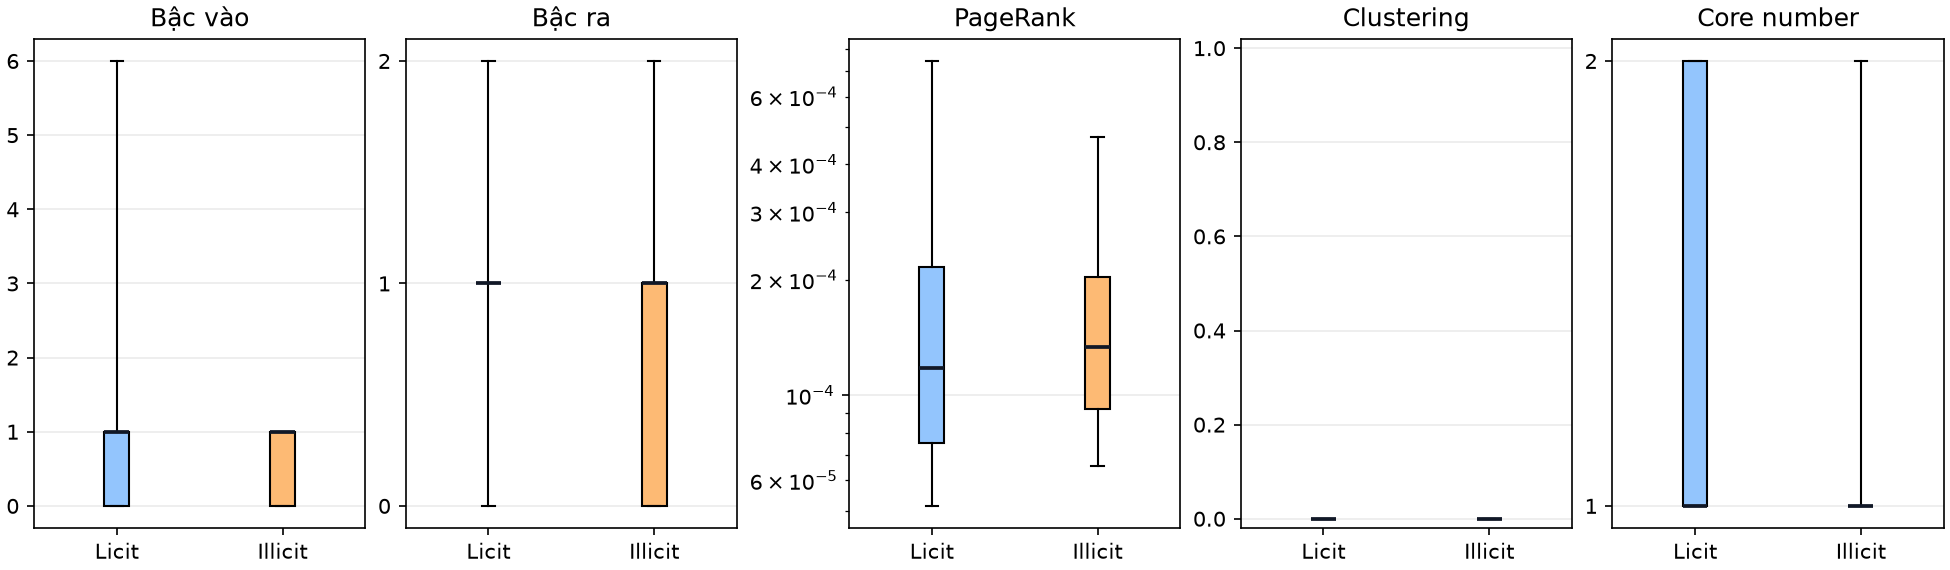

In [10]:
from matplotlib.ticker import MaxNLocator

boxplot_metrics = (
    ("in_degree", "Bậc vào", licit_degrees, illicit_degrees),
    ("out_degree", "Bậc ra", licit_degrees, illicit_degrees),
    ("pagerank", "PageRank", licit_structure, illicit_structure),
    ("clustering", "Clustering", licit_structure, illicit_structure),
    ("core_number", "Core number", licit_structure, illicit_structure),
)
fig, axes = plt.subplots(1, 5, figsize=(13, 3.8), layout="constrained")
for axis, (metric, title, licit, illicit) in zip(axes, boxplot_metrics):
    artists = axis.boxplot(
        [licit[metric], illicit[metric]], whis=(5, 95), showfliers=False, patch_artist=True,
        medianprops={"color": "#111827", "linewidth": 1.8},
    )
    for box, color in zip(artists["boxes"], ["#93c5fd", "#fdba74"]):
        box.set_facecolor(color)
    axis.set_xticks([1, 2], labels=["Licit", "Illicit"])
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.25)
    if metric == "pagerank":
        axis.set_yscale("log")
    elif metric == "clustering":
        axis.set_ylim(-0.02, 1.02)
    else:
        axis.yaxis.set_major_locator(MaxNLocator(integer=True))

structure_boxplot_path = figures_dir / "graph_structural_boxplots_by_class.png"
fig.savefig(structure_boxplot_path, dpi=150)
plt.close(fig)
display(Image(filename=str(structure_boxplot_path)))

## 3. Phân tích liên kết và motif

- **Homophily** so số cạnh illicit–illicit với mốc kỳ vọng khi xáo nhãn trong từng snapshot. Chỉ xét cạnh có nhãn ở cả hai đầu.
- **Khoảng cách** đếm số hop tới giao dịch illicit khác gần nhất, bỏ qua hướng cạnh. Ví dụ `illicit — unknown — illicit` dài hai hop.
- **Motif** gồm chuỗi có ít nhất hai node 1-vào-1-ra liên tiếp, fan-in, fan-out, vòng, tam giác và mẫu tán rồi gom `A → B → D` cùng `A → C → D`.

In [11]:
from collections import defaultdict

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra


def nearest_illicit_hops(snapshot_edges, node_indices, illicit_indices):
    if illicit_indices.size < 2:
        return np.full(illicit_indices.size, np.inf)

    sources, targets = np.searchsorted(node_indices, snapshot_edges)
    adjacency = csr_matrix(
        (np.ones(len(sources)), (sources, targets)),
        shape=(len(node_indices), len(node_indices)),
    )
    distances = dijkstra(adjacency, directed=False, indices=illicit_indices, unweighted=True)
    illicit_distances = distances[:, illicit_indices]
    np.fill_diagonal(illicit_distances, np.inf)
    return illicit_distances.min(axis=1)


def one_in_one_out_chains(graph):
    chain_nodes = [
        node for node in graph if graph.in_degree(node) == graph.out_degree(node) == 1
    ]
    chain_graph = graph.subgraph(chain_nodes)
    return [
        component for component in nx.weakly_connected_components(chain_graph)
        if len(component) >= 2 and chain_graph.subgraph(component).number_of_edges() < len(component)
    ]


def two_hop_branches(graph):
    intermediates_by_pair = defaultdict(list)
    for middle in graph:
        for source in graph.predecessors(middle):
            for target in graph.successors(middle):
                if source != target:
                    intermediates_by_pair[source, target].append(middle)
    return intermediates_by_pair


def find_transaction_motifs(graph):
    chains = one_in_one_out_chains(graph)
    intermediates_by_pair = two_hop_branches(graph)
    diamond_counts = defaultdict(int)
    diamond_count = 0
    for (source, target), intermediates in intermediates_by_pair.items():
        branch_count = len(intermediates)
        if branch_count >= 2:
            pair_diamonds = branch_count * (branch_count - 1) // 2
            diamond_count += pair_diamonds
            diamond_counts[source] += pair_diamonds
            diamond_counts[target] += pair_diamonds
            for middle in intermediates:
                diamond_counts[middle] += branch_count - 1

    cyclic_components = [
        component for component in nx.strongly_connected_components(graph) if len(component) > 1
    ]
    triangles = nx.triangles(graph.to_undirected())
    memberships = {
        "one_in_one_out_chain": set().union(*chains),
        "fan_out": {node for node, degree in graph.out_degree if degree >= 2},
        "fan_in": {node for node, degree in graph.in_degree if degree >= 2},
        "fan_out_fan_in_diamond": set(diamond_counts),
        "directed_cycle": set().union(*cyclic_components),
        "triangle": {node for node, count in triangles.items() if count},
    }
    counts = {
        "chain_count": len(chains),
        "fan_out_node_count": len(memberships["fan_out"]),
        "fan_in_node_count": len(memberships["fan_in"]),
        "diamond_count": diamond_count,
        "cyclic_component_count": len(cyclic_components),
        "triangle_count": sum(triangles.values()) // 3,
    }
    counts_by_node = {"fan_out_fan_in_count": diamond_counts, "triangle_count": triangles}
    return memberships, counts, counts_by_node

In [12]:
rng = np.random.default_rng(42)
permutation_count = 999
permuted_illicit_edges = np.zeros(permutation_count, dtype=np.int64)
homophily_rows, hop_frames, motif_snapshot_rows = [], [], []
motif_memberships = defaultdict(lambda: np.zeros(len(tx_ids), dtype=bool))
motif_node_counts = {
    name: np.zeros(len(tx_ids), dtype=np.int64)
    for name in ("fan_out_fan_in_count", "triangle_count")
}

for timestep in timesteps:
    graph = build_snapshot(node_timesteps, edge_index, int(timestep))
    assert nx.number_of_selfloops(graph) == 0
    node_indices = np.array(list(graph), dtype=np.int64)
    snapshot_edges = np.array(list(graph.edges), dtype=np.int64).reshape(-1, 2).T
    snapshot_labels = labels[node_indices]
    labeled_nodes = node_indices[snapshot_labels != -1]
    illicit_indices = np.flatnonzero(snapshot_labels == 1)
    illicit_nodes = node_indices[illicit_indices]
    labeled_edge_mask = (labels[snapshot_edges] != -1).all(axis=0)
    labeled_edges = snapshot_edges[:, labeled_edge_mask]
    observed = int((labels[labeled_edges] == 1).all(axis=0).sum())

    labeled_count = len(labeled_nodes)
    labeled_edge_count = labeled_edges.shape[1]
    illicit_count = len(illicit_nodes)
    expected = 0.0
    if labeled_count > 1:
        expected = (
            labeled_edge_count * illicit_count * (illicit_count - 1)
            / (labeled_count * (labeled_count - 1))
        )
    homophily_rows.append({
        "timestep": timestep,
        "labeled_node_count": labeled_count,
        "illicit_node_count": illicit_count,
        "labeled_edge_count": labeled_edge_count,
        "illicit_illicit_edge_count": observed,
        "expected_illicit_illicit_edge_count": expected,
        "enrichment": observed / expected if expected > 0 else np.nan,
    })

    if expected > 0:
        first, second = np.searchsorted(labeled_nodes, labeled_edges)
        illicit_flags = labels[labeled_nodes] == 1
        for permutation in range(permutation_count):
            shuffled = rng.permutation(illicit_flags)
            permuted_illicit_edges[permutation] += np.count_nonzero(shuffled[first] & shuffled[second])

    distances = nearest_illicit_hops(snapshot_edges, node_indices, illicit_indices)
    hop_frames.append(pd.DataFrame({
        "node_idx": illicit_nodes,
        "tx_id": tx_ids[illicit_nodes],
        "timestep": timestep,
        "nearest_illicit_hops": pd.array(np.where(np.isfinite(distances), distances, np.nan), dtype="Int64"),
    }))

    memberships, counts, counts_by_node = find_transaction_motifs(graph)
    for motif, members in memberships.items():
        motif_memberships[motif][list(members)] = True
    for motif, node_counts in counts_by_node.items():
        motif_node_counts[motif][list(node_counts)] = list(node_counts.values())
    motif_snapshot_rows.append({"timestep": timestep, **counts})

In [13]:
homophily = pd.DataFrame(homophily_rows)
nearest_hops = pd.concat(hop_frames, ignore_index=True).sort_values("node_idx")
motif_by_timestep = pd.DataFrame(motif_snapshot_rows)
motif_class_rows = []
for motif, members in motif_memberships.items():
    for class_name, class_id in (("licit", 0), ("illicit", 1)):
        class_mask = labels == class_id
        member_count = np.count_nonzero(members & class_mask)
        class_count = np.count_nonzero(class_mask)
        motif_class_rows.append({
            "motif": motif,
            "class": class_name,
            "node_count": class_count,
            "member_count": member_count,
            "member_rate": member_count / class_count,
        })
motif_by_class = pd.DataFrame(motif_class_rows)

assert np.array_equal(nearest_hops["node_idx"], np.flatnonzero(labels == 1))
assert nearest_hops["nearest_illicit_hops"].dropna().ge(1).all()
assert homophily["illicit_illicit_edge_count"].le(homophily["labeled_edge_count"]).all()
assert motif_by_class["member_rate"].between(0, 1).all()

homophily.to_csv(tables_dir / "graph_illicit_edge_homophily.csv", index=False)
nearest_hops.to_csv(tables_dir / "graph_illicit_nearest_hops.csv", index=False)
motif_by_timestep.to_csv(tables_dir / "graph_motif_by_timestep.csv", index=False)
motif_by_class.to_csv(tables_dir / "graph_motif_by_class.csv", index=False)

observed_total = homophily["illicit_illicit_edge_count"].sum()
expected_total = homophily["expected_illicit_illicit_edge_count"].sum()
permutation_p_value = (1 + np.count_nonzero(permuted_illicit_edges >= observed_total)) / (1 + permutation_count)
print(f"Cạnh illicit–illicit ghi nhận {observed_total:,}, kỳ vọng {expected_total:,.1f}.")
print(f"Mức làm giàu {observed_total / expected_total:.2f} lần, p-value hoán vị {permutation_p_value:.3f}.")
print(f"Khoảng cách trung vị {nearest_hops['nearest_illicit_hops'].median():g} hop.")
print(f"Số node illicit không tới được node illicit khác là {nearest_hops['nearest_illicit_hops'].isna().sum():,}.")

display(homophily.head())
display(motif_by_class)

Cạnh illicit–illicit ghi nhận 998, kỳ vọng 608.8.
Mức làm giàu 1.64 lần, p-value hoán vị 0.001.
Khoảng cách trung vị 2 hop.
Số node illicit không tới được node illicit khác là 0.


,timestep,labeled_node_count,illicit_node_count,labeled_edge_count,illicit_illicit_edge_count,expected_illicit_illicit_edge_count,enrichment
0,1,2147,17,1924,0,0.113583,0.000000
1,2,1117,18,858,0,0.210616,0.000000
2,3,1279,11,727,0,0.048924,0.000000
3,4,1440,30,1169,4,0.490807,8.149848
4,5,1882,8,1491,0,0.023586,0.000000


,motif,class,node_count,member_count,member_rate
0,one_in_one_out_chain,licit,42019,4659,0.110878
1,one_in_one_out_chain,illicit,4545,643,0.141474
2,fan_out,licit,42019,9799,0.233204
3,fan_out,illicit,4545,305,0.067107
4,fan_in,licit,42019,8434,0.200719
5,fan_in,illicit,4545,175,0.038504
6,fan_out_fan_in_diamond,licit,42019,1707,0.040624
7,fan_out_fan_in_diamond,illicit,4545,129,0.028383
8,directed_cycle,licit,42019,0,0.000000
9,directed_cycle,illicit,4545,0,0.000000


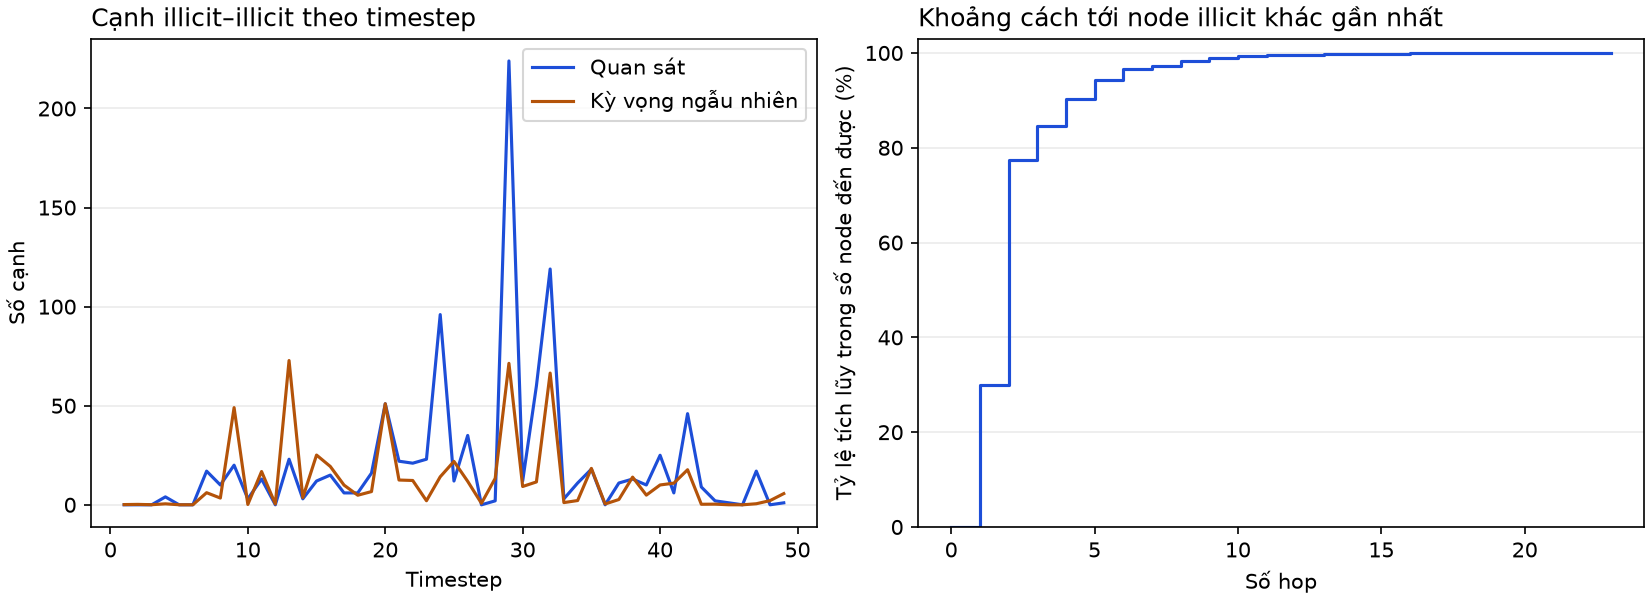

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(
    homophily["timestep"], homophily["illicit_illicit_edge_count"],
    label="Quan sát", color="#1d4ed8",
)
axes[0].plot(
    homophily["timestep"], homophily["expected_illicit_illicit_edge_count"],
    label="Kỳ vọng ngẫu nhiên", color="#b45309",
)
axes[0].set_title("Cạnh illicit–illicit theo timestep", loc="left")
axes[0].set_xlabel("Timestep")
axes[0].set_ylabel("Số cạnh")
axes[0].legend()

hop_counts = nearest_hops["nearest_illicit_hops"].dropna().value_counts().sort_index()
hop_cdf = hop_counts.cumsum() / hop_counts.sum() * 100
axes[1].step(np.r_[0, hop_cdf.index], np.r_[0, hop_cdf.to_numpy()], where="post", color="#1d4ed8")
axes[1].set_title("Khoảng cách tới node illicit khác gần nhất", loc="left")
axes[1].set_xlabel("Số hop")
axes[1].set_ylabel("Tỷ lệ tích lũy trong số node đến được (%)")
axes[1].set_ylim(0, 103)

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

link_figure_path = figures_dir / "graph_illicit_connections.png"
fig.savefig(link_figure_path, dpi=150)
plt.close(fig)
display(Image(filename=str(link_figure_path)))

## 4. Minh họa bằng ba subgraph thật

Ba ví dụ minh họa cạnh illicit–illicit, chuỗi 1-vào-1-ra và tán rồi gom. Mở HTML trong `outputs/subgraphs/` rồi rê chuột lên node để xem mã giao dịch, nhãn và bậc.

In [15]:
def example_snapshot(motif):
    counts = np.bincount(node_timesteps[(labels == 1) & motif_memberships[motif]])
    timestep = int(counts.argmax())
    return timestep, build_snapshot(node_timesteps, edge_index, timestep)


edge_excess = homophily["illicit_illicit_edge_count"] - homophily["expected_illicit_illicit_edge_count"]
edge_timestep = int(homophily.loc[edge_excess.idxmax(), "timestep"])
edge_graph = build_snapshot(node_timesteps, edge_index, edge_timestep)
illicit_edge = min((u, v) for u, v in edge_graph.edges if labels[u] == labels[v] == 1)

chain_timestep, chain_graph = example_snapshot("one_in_one_out_chain")
chain = min(
    (nodes for nodes in one_in_one_out_chains(chain_graph) if (labels[list(nodes)] == 1).any()),
    key=lambda nodes: (len(nodes), -np.count_nonzero(labels[list(nodes)] == 1), min(nodes)),
)
chain_path = list(nx.topological_sort(chain_graph.subgraph(chain)))
chain_path.insert(0, next(chain_graph.predecessors(chain_path[0])))
chain_path.append(next(chain_graph.successors(chain_path[-1])))

diamond_timestep, diamond_graph = example_snapshot("fan_out_fan_in_diamond")
diamond_candidates = []
for (source, target), branches in two_hop_branches(diamond_graph).items():
    if len(branches) >= 2:
        left, right = sorted(branches, key=lambda node: (labels[node] != 1, node))[:2]
        nodes = (source, left, right, target)
        illicit_count = np.count_nonzero(labels[list(nodes)] == 1)
        if illicit_count:
            diamond_candidates.append((-illicit_count, nodes))
_, (source, left, right, target) = min(diamond_candidates)

subgraph_examples = [
    (
        "subgraph_illicit_edge.html", "Cạnh trực tiếp giữa hai giao dịch illicit",
        edge_timestep, [[illicit_edge[0]], [illicit_edge[1]]], [illicit_edge],
    ),
    (
        "subgraph_transaction_chain.html", "Chuỗi giao dịch 1-vào-1-ra",
        chain_timestep, [[node] for node in chain_path], list(zip(chain_path, chain_path[1:])),
    ),
    (
        "subgraph_fan_out_fan_in.html", "Motif tán rồi gom",
        diamond_timestep, [[source], [left, right], [target]],
        [(source, left), (source, right), (left, target), (right, target)],
    ),
]

In [16]:
from html import escape
import json
import re

from pyvis.network import Network


label_styles = {
    1: ("illicit", "#b45309"),
    0: ("licit", "#1d4ed8"),
    -1: ("unknown", "#64748b"),
}
subgraphs_dir = project_root / "outputs" / "subgraphs"
subgraphs_dir.mkdir(parents=True, exist_ok=True)

example_rows = []
for filename, title, timestep, levels, example_edges in subgraph_examples:
    network = Network(
        height="440px", width="100%", directed=True, bgcolor="#f8fafc", cdn_resources="in_line",
    )
    for level, nodes in enumerate(levels):
        for node in nodes:
            label, color = label_styles[int(labels[node])]
            network.add_node(
                node,
                label=str(tx_ids[node]),
                level=level,
                color=color,
                title=(
                    f"tx_id {tx_ids[node]} | {label} | "
                    f"Bậc vào {in_degree[node]} | Bậc ra {out_degree[node]}"
                ),
            )

    for source, target in example_edges:
        network.add_edge(source, target, arrows="to", color="#475569", width=2)

    network.set_options(json.dumps({
        "layout": {"hierarchical": {
            "enabled": True, "direction": "LR", "sortMethod": "directed", "levelSeparation": 180,
        }},
        "physics": {"enabled": False},
        "nodes": {"shape": "dot", "size": 15, "font": {"size": 16, "color": "#0f172a"}},
        "edges": {"smooth": False},
        "interaction": {"hover": True},
    }))

    legend = " &nbsp; ".join(
        f'<span style="color:{color}">●</span> {label}' for label, color in label_styles.values()
    )
    header = (
        '<header style="font:16px system-ui,sans-serif;margin:24px 20px">'
        f'<h1 style="font-size:24px;margin-bottom:8px">{escape(title)}</h1>'
        f'<p>Timestep {timestep} &ensp; {legend}</p></header>'
    )
    html = network.generate_html(notebook=False)
    # PyVis 0.3.2 vẫn thêm Bootstrap CDN vào mẫu HTML ngay cả khi đã nhúng vis-network.
    html = re.sub(
        r'<(?:link|script)\s+[^>]*(?:href|src)="https://cdn\.jsdelivr\.net/npm/bootstrap[^>]+>'
        r'(?:\s*</script>)?',
        "",
        html,
    )
    html = html.replace("<body>", f"<body>{header}", 1)
    (subgraphs_dir / filename).write_text(html, encoding="utf-8")

    example_rows.append({
        "ví dụ": title,
        "timestep": timestep,
        "số node": sum(map(len, levels)),
        "số cạnh": len(example_edges),
        "file": filename,
    })

display(pd.DataFrame(example_rows))

,ví dụ,timestep,số node,số cạnh,file
0,Cạnh trực tiếp giữa hai giao dịch illicit,29,2,1,subgraph_illicit_edge.html
1,Chuỗi giao dịch 1-vào-1-ra,29,4,3,subgraph_transaction_chain.html
2,Motif tán rồi gom,42,4,4,subgraph_fan_out_fan_in.html


### Ảnh PNG cho báo cáo và slide

Ảnh `subgraph_*.png` trong `outputs/figures/` dùng cùng node, cạnh và màu nhãn với bản HTML.

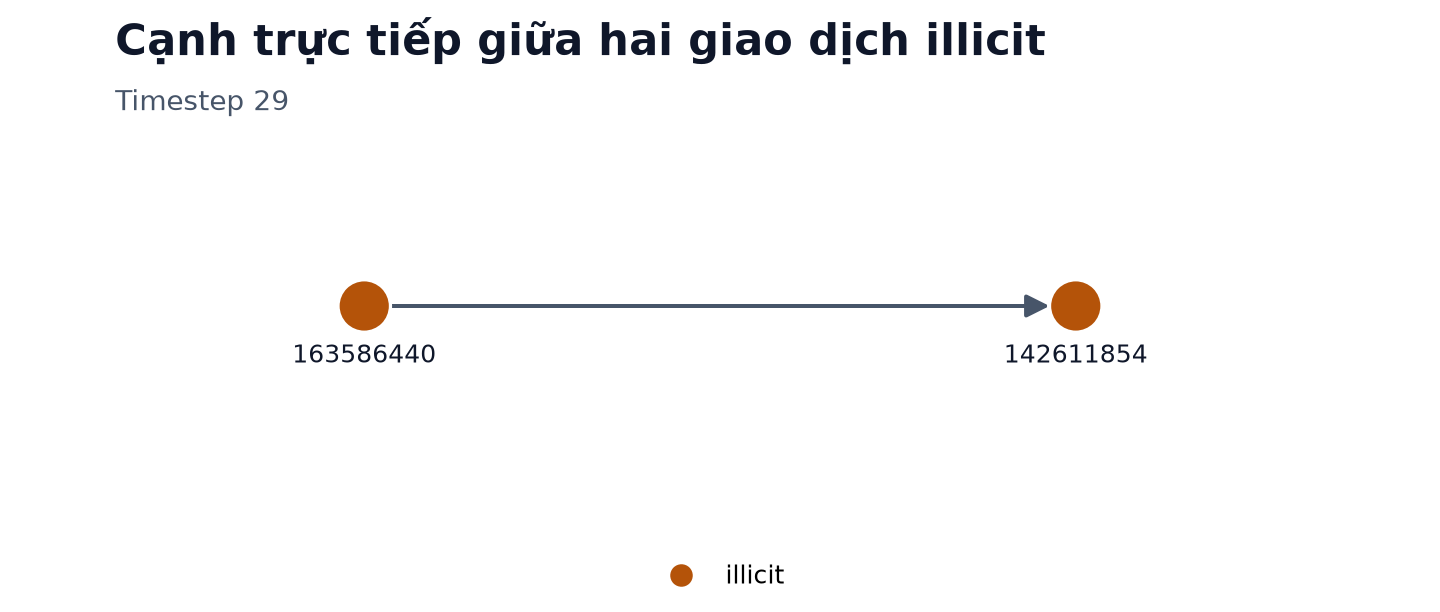

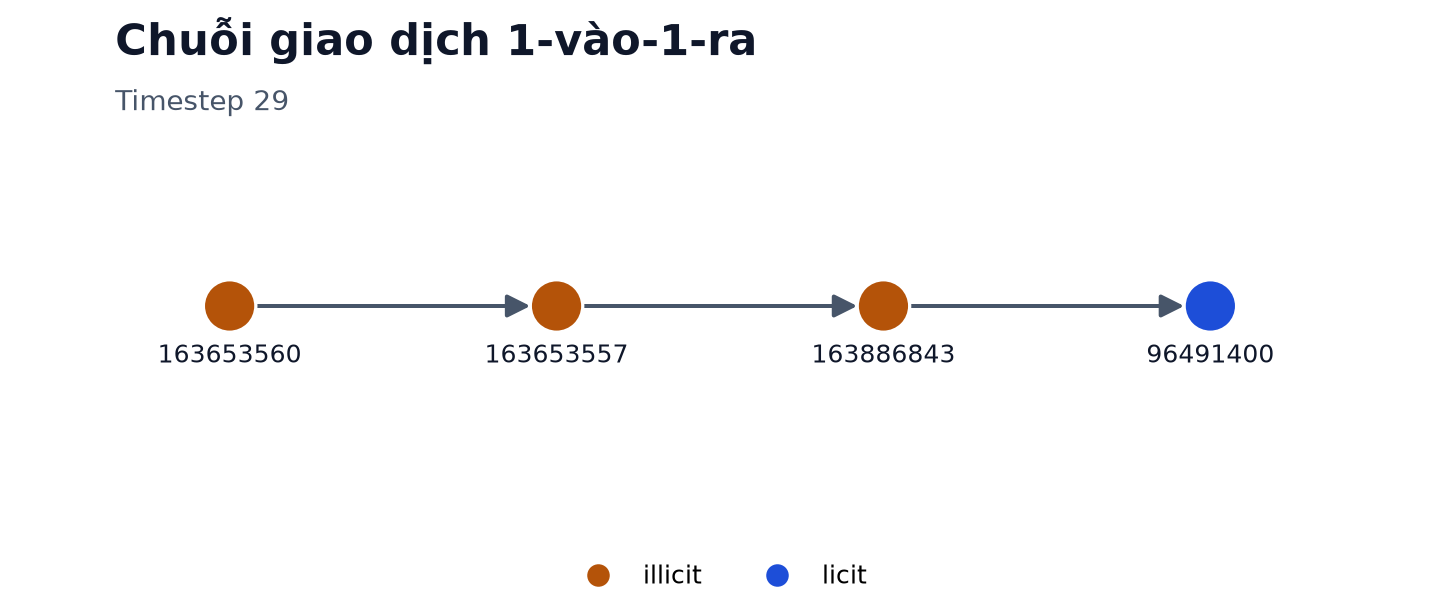

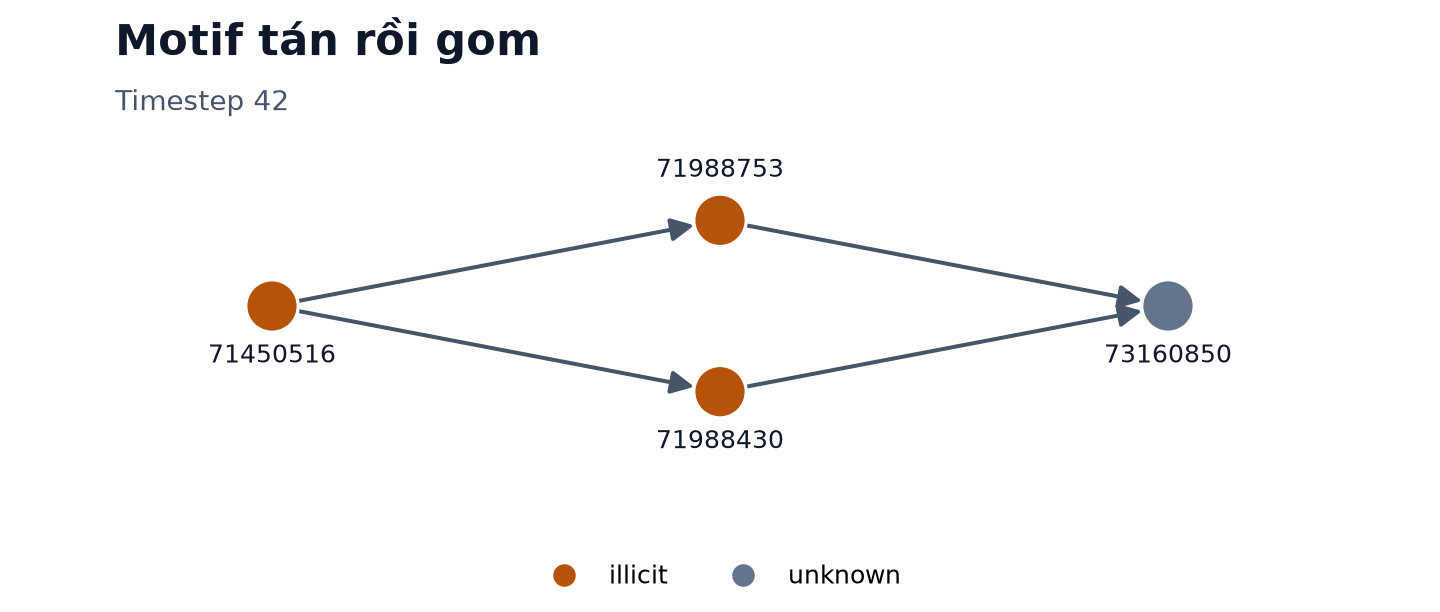

In [17]:
from matplotlib.lines import Line2D


for filename, title, timestep, levels, example_edges in subgraph_examples:
    positions = {
        node: (level, (len(nodes) - 1) / 2 - row)
        for level, nodes in enumerate(levels)
        for row, node in enumerate(nodes)
    }
    nodes = list(positions)
    example_graph = nx.DiGraph()
    example_graph.add_nodes_from(nodes)
    example_graph.add_edges_from(example_edges)

    fig, axis = plt.subplots(figsize=(8, 3.4), facecolor="white")
    fig.subplots_adjust(left=0.08, right=0.92, bottom=0.22, top=0.78)
    fig.text(0.08, 0.91, title, fontsize=17, weight="bold", color="#0f172a")
    fig.text(0.08, 0.82, f"Timestep {timestep}", fontsize=11, color="#475569")

    node_size = 440
    nx.draw_networkx_edges(
        example_graph, positions, ax=axis, arrows=True, arrowsize=19,
        edge_color="#475569", width=1.6, node_size=node_size,
    )
    nx.draw_networkx_nodes(
        example_graph, positions, ax=axis, nodelist=nodes, node_size=node_size,
        node_color=[label_styles[int(labels[node])][1] for node in nodes],
        edgecolors="white", linewidths=1.3,
    )
    for node, (x, y) in positions.items():
        above = y > 0
        axis.annotate(
            str(tx_ids[node]), (x, y), xytext=(0, 15 if above else -15),
            textcoords="offset points", ha="center", va="bottom" if above else "top",
            fontsize=10, color="#0f172a", annotation_clip=False,
        )

    class_ids = {int(labels[node]) for node in nodes}
    handles = [
        Line2D([], [], marker="o", linestyle="none", color=color, label=label, markersize=8)
        for class_id, (label, color) in label_styles.items()
        if class_id in class_ids
    ]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
    axis.set_xlim(-0.35, len(levels) - 0.65)
    axis.set_ylim(-1.0, 1.0)
    axis.set_axis_off()

    png_path = figures_dir / Path(filename).with_suffix(".png").name
    fig.savefig(png_path, dpi=180)
    plt.close(fig)
    display(Image(filename=str(png_path), width=720))

## 5. Kết luận của P1

- Illicit có xu hướng bậc ra và core number thấp hơn, với hiệu ứng **−0,190** và **−0,173**.
- Quan sát **998 cạnh illicit–illicit** so với **608,8 cạnh** kỳ vọng. Khoảng cách trung vị là **2 hop**.
- **14,1% illicit** và **11,1% licit** tham gia chuỗi 1-vào-1-ra.

Đây là kết quả thăm dò vì các giao dịch cùng snapshot có thể phụ thuộc nhau.

## 6. Bàn giao feature cho P2

`graph_features.parquet` có **203.769 dòng** và **11 feature cấu trúc** gồm 5 feature cơ bản, 4 cờ motif và 2 số đếm motif. P2 đối chiếu `node_idx` và `tx_id` với P0 trước khi ghép vào `X_local`.

Feature tính từ toàn bộ cạnh trong từng snapshot. Các phép phân tích cần nhãn, như homophily và khoảng cách tới illicit, dùng cho EDA.

In [18]:
graph_features = structural_features.assign(
    one_in_one_out_chain=motif_memberships["one_in_one_out_chain"],
    fan_out=motif_memberships["fan_out"],
    fan_in=motif_memberships["fan_in"],
    fan_out_fan_in_count=motif_node_counts["fan_out_fan_in_count"],
    in_directed_cycle=motif_memberships["directed_cycle"],
    triangle_count=motif_node_counts["triangle_count"],
)

for metric, total_column, nodes_per_motif in (
    ("fan_out_fan_in_count", "diamond_count", 4),
    ("triangle_count", "triangle_count", 3),
):
    counts_by_timestep = np.bincount(node_timesteps, weights=graph_features[metric])[1:]
    np.testing.assert_array_equal(counts_by_timestep, motif_by_timestep[total_column] * nodes_per_motif)

assert graph_features.shape == (203_769, 13)
np.testing.assert_array_equal(graph_features["node_idx"], np.arange(len(tx_ids)))
np.testing.assert_array_equal(graph_features["tx_id"], tx_ids)
assert graph_features["tx_id"].is_unique
assert np.isfinite(graph_features.to_numpy(dtype=float)).all()

graph_features_path = tables_dir / "graph_features.parquet"
graph_features.to_parquet(graph_features_path, engine="pyarrow", index=False)
pd.testing.assert_frame_equal(
    pd.read_parquet(graph_features_path, engine="pyarrow"), graph_features
)
print(f"Đã xác minh {len(graph_features):,} dòng và 11 feature tại {graph_features_path}.")
display(graph_features.head())

Đã xác minh 203,769 dòng và 11 feature tại d:\BTL_AIT3003_ULB-Credit-Card-Fraud\outputs\tables\graph_features.parquet.


,node_idx,tx_id,in_degree,out_degree,pagerank,clustering,core_number,one_in_one_out_chain,fan_out,fan_in,fan_out_fan_in_count,in_directed_cycle,triangle_count
0,0,230425980,1,1,0.000105,0.000000,1,True,False,False,0,False,0
1,1,5530458,1,1,0.000130,0.000000,1,True,False,False,0,False,0
2,2,232022460,1,2,0.000129,0.000000,1,False,True,False,0,False,0
3,3,232438397,160,1,0.007169,0.000621,2,False,False,True,1,False,8
4,4,230460314,2,8,0.000054,0.266667,5,False,True,True,24,False,12
